# Redes siamesas con triplet loss

Aprendizaje de una métrica de similitud entre imágenes: una red siamesa transforma cada imagen en un vector de 64 o 128 dimensiones, entrenada para que imágenes de la misma clase queden cerca y las de clases distintas, lejos. Se aplica a dos conjuntos:

1. **Fashion-MNIST** (prendas de ropa en escala de grises), con una red convolucional entrenada desde cero.
2. **Flores** (fotografías en color de 5 especies), con MobileNetV2 preentrenada como extractor de características.

La calidad del espacio aprendido se mide clasificando cada imagen de prueba por su vecino más cercano en ese espacio.

## 1. Triplet loss

Cada ejemplo de entrenamiento es una tripleta: un **ancla** (A), un **positivo** (P) de la misma clase y un **negativo** (N) de otra clase. Las tres imágenes pasan por la misma red (de ahí «siamesa»: pesos compartidos) y la pérdida exige que el ancla quede más cerca del positivo que del negativo por al menos un margen α:

$$\mathcal{L}(A, P, N) = \max\left(\|f(A) - f(P)\|^2 - \|f(A) - f(N)\|^2 + \alpha,\ 0\right)$$

Los vectores de salida se normalizan a longitud 1, así que la distancia al cuadrado entre dos vectores está entre 0 y 4. Se usa α = 0,2.

In [1]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

tf.keras.utils.set_random_seed(42)
rng = np.random.default_rng(42)
MARGEN = 0.2


def triplet_loss(y_true, y_pred):
    ancla, positivo, negativo = y_pred[0], y_pred[1], y_pred[2]
    d_pos = tf.reduce_sum(tf.square(ancla - positivo), axis=-1)
    d_neg = tf.reduce_sum(tf.square(ancla - negativo), axis=-1)
    return tf.reduce_mean(tf.maximum(d_pos - d_neg + MARGEN, 0.0))


def crear_tripletas(imagenes, etiquetas, por_clase):
    """Para cada clase, `por_clase` tripletas (ancla y positivo de la clase, negativo de otra)."""
    indices = []
    for c in np.unique(etiquetas):
        pos = np.where(etiquetas == c)[0]
        neg = np.where(etiquetas != c)[0]
        indices.append(np.stack([rng.choice(pos, por_clase), rng.choice(pos, por_clase),
                                 rng.choice(neg, por_clase)], axis=1))
    indices = rng.permutation(np.concatenate(indices))   # mezcladas: validation_split toma las últimas
    return imagenes[indices]          # forma: (n, 3, alto, ancho, canales)


def red_siamesa(base, forma):
    entrada = tf.keras.Input(shape=(3,) + forma)
    vectores = [base(entrada[:, i]) for i in range(3)]
    salida = layers.Lambda(lambda v: tf.stack(v, axis=0))(vectores)
    modelo = tf.keras.Model(entrada, salida)
    modelo.compile(loss=triplet_loss, optimizer='adam')
    return modelo


def evaluar_espacio(vectores, etiquetas, nombres, titulo):
    """Clasifica cada imagen por su vecino más cercano (excluida ella misma) en el espacio aprendido."""
    similitud = vectores @ vectores.T          # vectores normalizados: mayor producto = menor distancia
    np.fill_diagonal(similitud, -np.inf)
    vecino = etiquetas[np.argmax(similitud, axis=1)]
    exactitud = (vecino == etiquetas).mean()
    print(f'{titulo}: exactitud del vecino más cercano = {exactitud:.3f}')
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(confusion_matrix(etiquetas, vecino, normalize='true'),
                           display_labels=nombres).plot(ax=ax, xticks_rotation='vertical',
                                                        values_format='.2f', cmap='Blues', colorbar=False)
    ax.set_title(f'{titulo}: clase del vecino más cercano')
    plt.tight_layout()
    plt.show()
    return exactitud


def mostrar_distancias(base, imagenes, etiquetas, nombres, n_consultas=3, cmap=None):
    """Para algunas imágenes de consulta, distancia a un ejemplo de cada clase."""
    fig, ejes = plt.subplots(n_consultas, len(nombres) + 1, figsize=(1.6 * (len(nombres) + 1), 2.1 * n_consultas))
    for fila, c in enumerate(rng.choice(len(nombres), n_consultas, replace=False)):
        consulta = imagenes[rng.choice(np.where(etiquetas == c)[0])]
        v = base(consulta[None]).numpy()[0]
        ejes[fila, 0].imshow(consulta.squeeze(), cmap=cmap)
        ejes[fila, 0].set_title('consulta', fontsize=9)
        for k in range(len(nombres)):
            ejemplo = imagenes[rng.choice(np.where(etiquetas == k)[0])]
            d = np.sum((v - base(ejemplo[None]).numpy()[0]) ** 2)
            eje = ejes[fila, k + 1]
            eje.imshow(ejemplo.squeeze(), cmap=cmap)
            eje.set_title(f'{nombres[k]}\n{d:.2f}', fontsize=8, color='green' if k == c else 'gray')
        for eje in ejes[fila]:
            eje.axis('off')
    fig.suptitle('Distancia al cuadrado entre la consulta y un ejemplo de cada clase (en verde, la clase de la consulta)', fontsize=10)
    plt.tight_layout()
    plt.show()

## 2. Fashion-MNIST con una red convolucional

70.000 imágenes de 28 × 28 píxeles en 10 clases de prendas. La red base tiene tres capas convolucionales y una capa densa que produce vectores de 64 dimensiones. Se entrena con 100.000 tripletas (10.000 por clase), reservando el 15 % para validación.

Tripletas de entrenamiento: (100000, 3, 28, 28, 1)


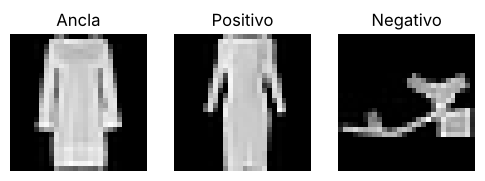

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train, x_test = x_train[..., None], x_test[..., None]   # se dejan en uint8; la red reescala a [0, 1]
prendas = ['Camiseta', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Tenis', 'Bolso', 'Botín']

tripletas = crear_tripletas(x_train, y_train, 10_000)
print('Tripletas de entrenamiento:', tripletas.shape)

fig, ejes = plt.subplots(1, 3, figsize=(6, 2.3))
for eje, img, titulo in zip(ejes, tripletas[0], ['Ancla', 'Positivo', 'Negativo']):
    eje.imshow(img.squeeze(), cmap='gray')
    eje.set_title(titulo)
    eje.axis('off')
plt.show()

Parámetros de la red base: 494,144


Epoch 1/8


665/665 - 58s - 88ms/step - loss: 0.0251 - val_loss: 0.0214


Epoch 2/8


665/665 - 80s - 121ms/step - loss: 0.0164 - val_loss: 0.0183


...

665/665 - 55s - 82ms/step - loss: 0.0071 - val_loss: 0.0156


Epoch 7/8


665/665 - 82s - 123ms/step - loss: 0.0060 - val_loss: 0.0151


Epoch 8/8


665/665 - 82s - 124ms/step - loss: 0.0047 - val_loss: 0.0150


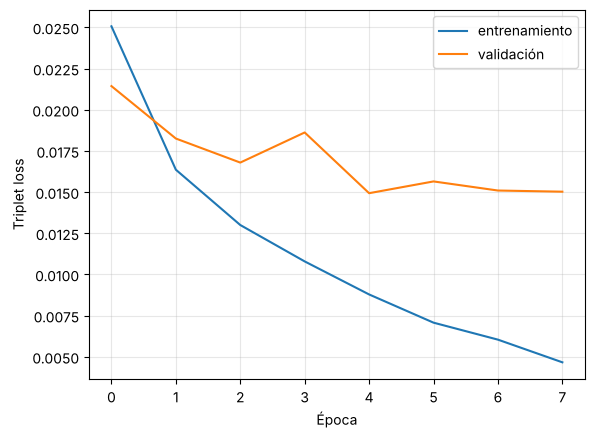

In [3]:
entrada = tf.keras.Input(shape=(28, 28, 1))
x = layers.Rescaling(1 / 255)(entrada)
x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
x = layers.Flatten()(x)
x = layers.Dense(64)(x)
salida = layers.UnitNormalization()(x)
base_fashion = tf.keras.Model(entrada, salida, name='base_convolucional')
print(f'Parámetros de la red base: {base_fashion.count_params():,}')

siamesa = red_siamesa(base_fashion, (28, 28, 1))
historia = siamesa.fit(tripletas, np.zeros(len(tripletas)), epochs=8, batch_size=128,
                       validation_split=0.15, verbose=2)

plt.plot(historia.history['loss'], label='entrenamiento')
plt.plot(historia.history['val_loss'], label='validación')
plt.xlabel('Época')
plt.ylabel('Triplet loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

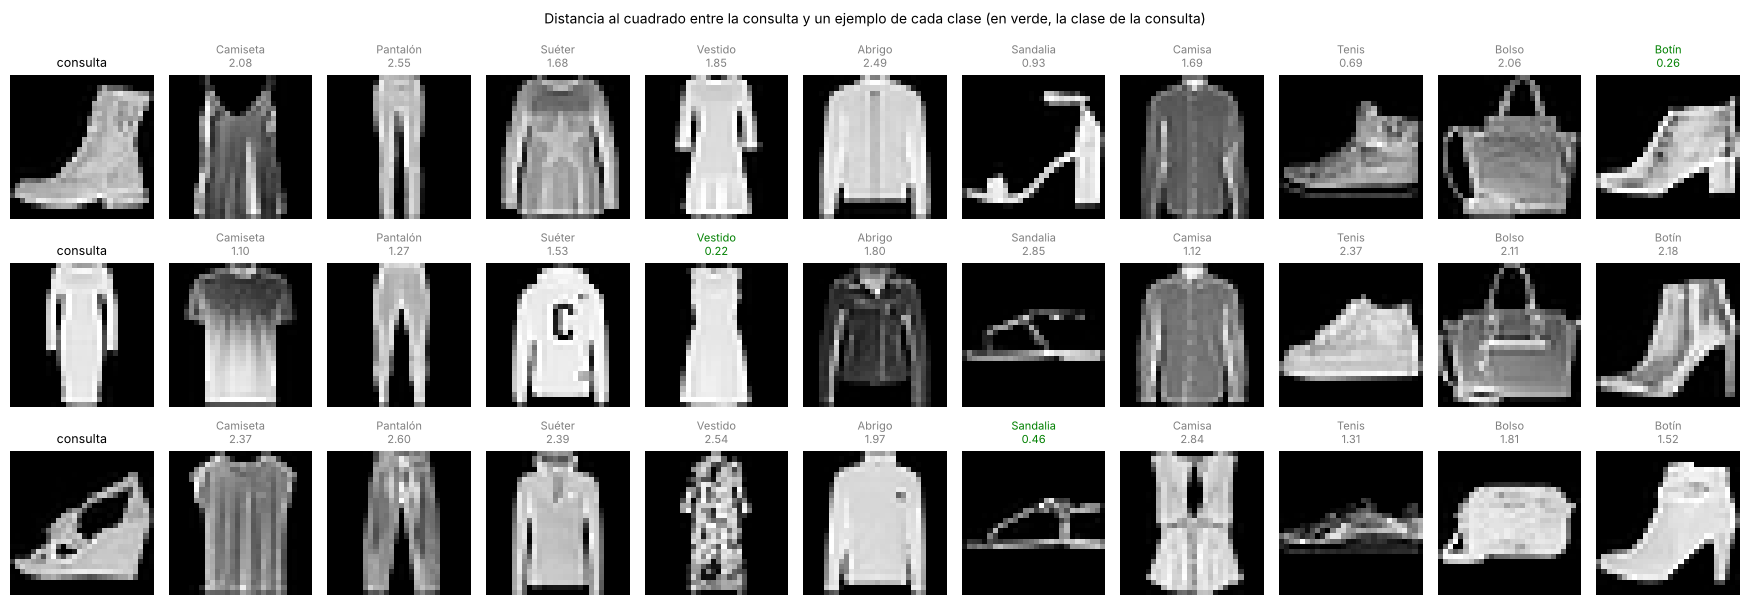

Fashion-MNIST (10.000 imágenes de prueba): exactitud del vecino más cercano = 0.870


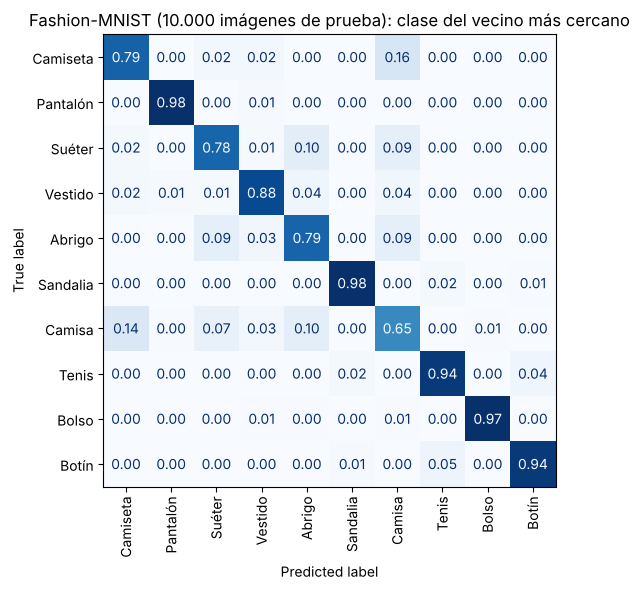

In [4]:
mostrar_distancias(base_fashion, x_test, y_test, prendas, cmap='gray')
vectores_fashion = base_fashion.predict(x_test, verbose=0)
exactitud_fashion = evaluar_espacio(vectores_fashion, y_test, prendas, 'Fashion-MNIST (10.000 imágenes de prueba)')

## 3. Flores con MobileNetV2 preentrenada

3.670 fotografías de 5 especies. Con tan pocas imágenes no conviene entrenar una red convolucional desde cero: se usa MobileNetV2 preentrenada en ImageNet, congelada, y solo se entrena una capa densa que proyecta sus características a vectores de 128 dimensiones. Las imágenes se reducen a 96 × 96 píxeles y se separa un 20 % para la evaluación.

Como MobileNetV2 no se entrena, sus características (1.280 por imagen) se calculan una sola vez y la red siamesa se entrena sobre ellas; el resultado es el mismo que pasar cada tripleta de imágenes por la red completa, con una fracción del cómputo. Al final se unen las dos partes en un solo modelo que recibe la imagen.

In [5]:
archivo = tf.keras.utils.get_file(
    'flower_photos.tgz', 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',
    extract=True)
carpeta = next(p.parent for p in pathlib.Path(archivo).parent.rglob('daisy') if p.is_dir())

TAM = (96, 96)
def cargar(subconjunto):
    ds = tf.keras.utils.image_dataset_from_directory(carpeta, validation_split=0.2, subset=subconjunto,
                                                     seed=1, image_size=TAM, batch_size=None)
    nombres = ds.class_names
    imagenes, etiquetas = zip(*ds.as_numpy_iterator())
    return np.array(imagenes), np.array(etiquetas), nombres

f_train, fy_train, flores = cargar('training')
f_test, fy_test, _ = cargar('validation')
print('Entrenamiento:', f_train.shape, '| Evaluación:', f_test.shape)

Found 3670 files belonging to 5 classes.


Using 2936 files for training.


Found 3670 files belonging to 5 classes.


Using 734 files for validation.


Entrenamiento: (2936, 96, 96, 3) | Evaluación: (734, 96, 96, 3)


Las imágenes se dejan en la escala original de 0 a 255, porque el preprocesamiento propio de MobileNetV2 (`preprocess_input`) es el que las lleva al rango que espera la red.

In [6]:
entrada = tf.keras.Input(shape=TAM + (3,))
mobilenet = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet',
                                              input_shape=TAM + (3,), pooling='avg')
mobilenet.trainable = False
caracteristicas = tf.keras.Model(
    entrada, mobilenet(tf.keras.applications.mobilenet_v2.preprocess_input(entrada), training=False))
c_train = caracteristicas.predict(f_train, batch_size=64, verbose=0)
print('Características de entrenamiento:', c_train.shape)

entrada_c = tf.keras.Input(shape=(c_train.shape[1],))
cabeza = tf.keras.Model(entrada_c, layers.UnitNormalization()(layers.Dense(128)(entrada_c)), name='proyeccion')

tripletas_f = crear_tripletas(c_train, fy_train, 1_000)
siamesa_f = red_siamesa(cabeza, (c_train.shape[1],))
historia_f = siamesa_f.fit(tripletas_f, np.zeros(len(tripletas_f)), epochs=5, batch_size=64,
                           validation_split=0.15, verbose=2)

base_flores = tf.keras.Model(entrada, cabeza(caracteristicas(entrada)), name='base_mobilenet')

Características de entrenamiento: (2936, 1280)
Epoch 1/5


67/67 - 1s - 10ms/step - loss: 0.0720 - val_loss: 0.0513


Epoch 2/5


67/67 - 0s - 4ms/step - loss: 0.0149 - val_loss: 0.0490


Epoch 3/5


67/67 - 0s - 5ms/step - loss: 0.0028 - val_loss: 0.0485


Epoch 4/5


67/67 - 0s - 4ms/step - loss: 8.3917e-04 - val_loss: 0.0473


Epoch 5/5


67/67 - 0s - 5ms/step - loss: 6.0091e-04 - val_loss: 0.0461


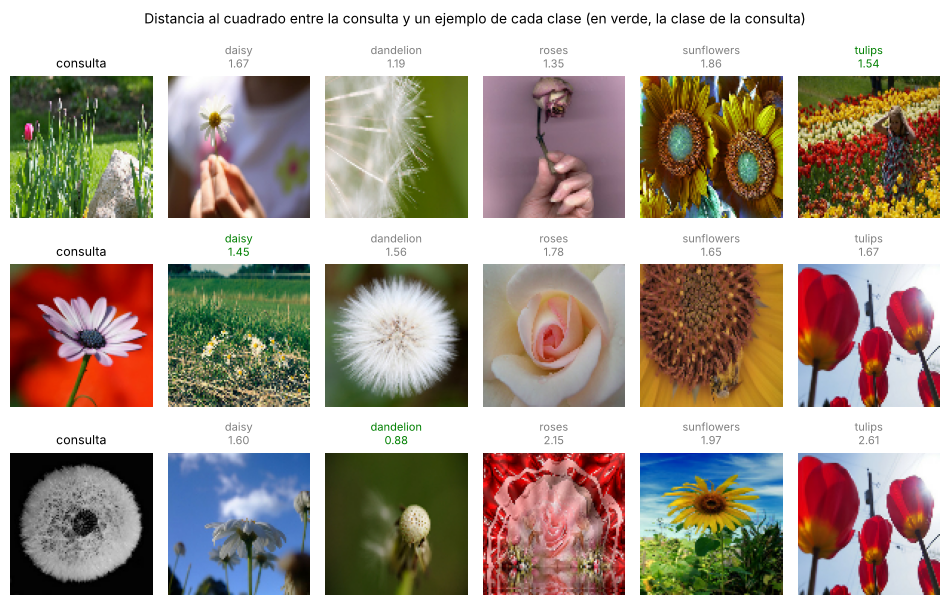

Flores (734 imágenes de evaluación): exactitud del vecino más cercano = 0.824


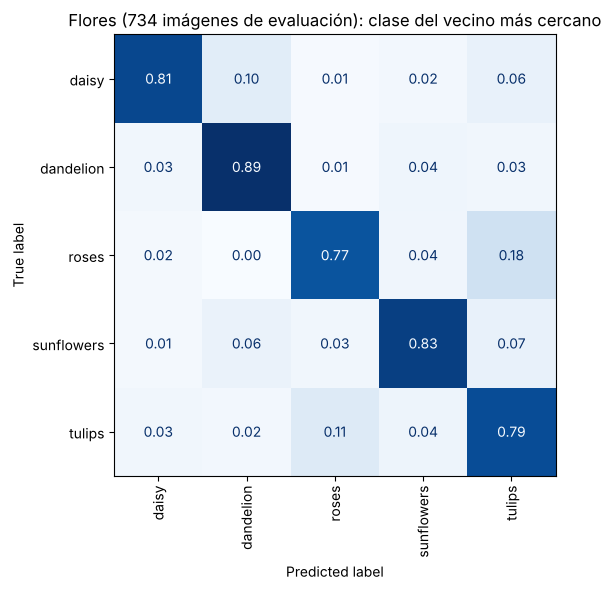

In [7]:
mostrar_distancias(base_flores, f_test.astype('uint8'), fy_test, flores)
vectores_flores = base_flores.predict(f_test, verbose=0)
exactitud_flores = evaluar_espacio(vectores_flores, fy_test, flores, 'Flores (734 imágenes de evaluación)')

## 4. Análisis

**Fashion-MNIST.** Clasificando cada imagen de prueba por su vecino más cercano en el espacio aprendido, acierta en el 87,0 % de los casos, sin que la red haya visto nunca una etiqueta como objetivo: solo aprendió a acercar y alejar. Pantalones, sandalias y bolsos quedan casi perfectamente separados (97–98 %), y el calzado solo se confunde entre sí (tenis y botines, 4–5 %). Los errores se concentran en las prendas de torso, que a 28 × 28 píxeles comparten silueta: la camisa es la clase más difícil (65 %), confundida con camiseta (14 %), abrigo (10 %) y suéter (7 %), y suéter y abrigo se intercambian alrededor del 10 %. La pérdida de validación baja de 0,021 a 0,015 en 8 épocas mientras la de entrenamiento llega a 0,005: hay algo de sobreajuste, pero la validación no empeora.

**Flores.** Entrenando únicamente una capa densa sobre las características congeladas de MobileNetV2, el vecino más cercano acierta en el 82,4 % de las 734 imágenes de evaluación. El diente de león es la especie mejor separada (89 %) y la confusión principal es entre rosas y tulipanes (18 % y 11 %), dos flores de colores y formas parecidos a 96 × 96 píxeles; las margaritas se confunden con dientes de león en un 10 %. Aquí el sobreajuste es claro: la pérdida de entrenamiento cae casi a cero en tres épocas mientras la de validación se queda cerca de 0,047, porque con 1.280 características y solo 2.936 fotos la capa memoriza las tripletas de entrenamiento con facilidad.

Las figuras de consultas comparan con un solo ejemplo por clase, así que son ilustrativas y ruidosas: en Fashion-MNIST la clase correcta queda la más cercana en las tres consultas (y el calzado, cerca entre sí); en flores, en dos de tres, porque el tulipán de la primera fila, pequeño dentro de una foto de pasto, queda más cerca del diente de león. Por eso la evaluación usa todas las imágenes. La evaluación usa como galería las propias imágenes de prueba (cada una se compara con las demás), así que mide qué tan bien agrupa el espacio, no el desempeño de un sistema que buscara en una base de imágenes ya etiquetadas.